In [ ]:
""" Import required libraries
"""
import torch
import scipy.io as sio
import numpy as np
import netCDF4 as nc
import deepxde as dde
import pinnicle as pinn
import matplotlib.tri as tri
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap, LogNorm
from matplotlib.artist import Artist
from matplotlib.path import Path
from mpl_toolkits.axes_grid1 import make_axes_locatable
from tqdm import tqdm
import cmcrameri.cm as cmc
dde.config.set_default_float('float32')
import cartopy.crs as ccrs
import matplotlib.ticker as mticker
from pyproj import Transformer
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerBase
from matplotlib.image import BboxImage
from matplotlib.transforms import Bbox

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


Set the default float type to float64
Set the default float type to float32


In [2]:
cd /private/var/phys-admin/Documents/Jakob/MC-SSA

/private/var/phys-admin/Documents/Jakob/MC-SSA


/opt/miniconda3/envs/ddeenv/lib/python3.10/site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [3]:
""" specify data paths
"""
glacier = "Byrd-BMap3GL"
# glacier = "Cook"
# glacier = "Ninnis"
# glacier = "Reid_Northcliff"
# glacier = "Denman2"
# glacier = "Denman2corrected"
# glacier = "PIG"
# glacier = "ByrdRoss"
# glacier = 'WAnt'
# glacier = 'Amery'
# glacier = 'EAnt'
# glacier = 'Shakelton'
# glacier = 'Mertz'
# glacier = 'AmeryInterior'

# glacier = f'{glacier}SCAR'

size = "30" + "ma"

FFT = False

# model = "MC-SSA"
# model = "MC-MOLHO"
# model = "MC-MOLHO-steady"
# model = "MC-LLIBOUTRY"
# model = "MC_exact"
model = "MC_exact_Helm"

homepath = '/private/var/phys-admin/Documents/Jakob/MC-SSA'
datapath = homepath + '/data/'
figurepath = homepath + '/figures/'
folder = homepath + '/MC-SSA/domains/'

# for Gadi runs
outline = folder + f"{glacier}-{size}-vertices.exp"
outlinePLOT = folder + f"{glacier}-57ma-vertices.exp"
# H_radar = datapath + 'BedMap3-radar-thk-profiles/bedmap3_radar_thk_masked.mat'
H_radar = folder + 'bedmap3_radar_thk_profiles.mat'
dHdt_il = folder + 'ItsLIVE_dHdt_2013-18_mps.mat'
smb_noell = folder + 'Noell_RACMO_smb_2013-17_mps.mat'
app_mb = folder + 'apparent_mass_balance_2013-17_mps.mat'

# # for normal runs
# outline = folder + glacier + '_glacier_outline_vertices.exp'
# measX = folder + glacier + '_measures_vx_mps.mat'
# measY = folder + glacier + '_measures_vy_mps.mat'
# H_radar = folder + glacier + '_bedmap3_radar_thk.mat'
# dHdt_il = folder + glacier + '_dHdt_2013-18_mps.mat'    
# smb_noell = folder + glacier + '_smb_2013-17_mps.mat'

bm3 = datapath + 'measures_data/BedMachineAntarctica-v3.nc'
bmap3 = datapath + '/BedMap3-radar-thk-profiles/bedmap3.nc'
meas = datapath + 'measures_data/antarctic_ice_vel_phase_map_v01_seconds.nc'

# smb2020 = datapath + folder + 'SMB-Noel2023/smb_rec.1979-2021.RACMO2.3p2_ANT27_ERA5-3h.AIS.2km.YY.nc'
# dHdt2020 = datapath + folder + 'itslive_data/ANT_G1920_GroundedIceHeight_v01.nc'

outFile = glacier
modelFolder = 'MC-SSA/Models/' + outFile 

In [4]:
""" create the PINNICLE parameter dictionary
"""
hp = {}
hp['epochs'] = 1000
hp['learning_rate'] = 1e-3
hp['loss_function'] = 'MSE'
hp['save_path'] = modelFolder
hp['is_save'] = False
hp['is_plot'] = True

hp["fft"] = FFT
hp["sigma"] = [1.0, 10.0, 100.0]
hp["num_fourier_feature"] = 50

# hp["activation"] = "SiLU" # "tanh" #
hp["activation"] = "SiLU" # ["SiLU"]*8 + ["tanh"]
hp["initializer"] = "Glorot uniform"
hp["num_neurons"] = 50
# hp['num_neurons'] = [400,200,50,25,25,50,100,100,]
hp["num_layers"] = 8
hp["optimizer"] = "L-BFGS"

hp['shapefile'] = outline
hp['num_collocation_points'] = 5000

MC = {}
MC_SSA = {}
SSA_weak = {}
# SSA['scalar_variables'] = {"B":1.26802073401e+08}
MC_MOLHO = {}
MC_LLIBOUTRY = {}
MC_exact = {}
MC_exact_Helm = {}
Lliboutry_sliding = {}
Lliboutry_shear = {}
# hp["equations"] = {"SSA_MCsteady Taub":SSA}
# hp["equations"] = {"MC_exact":MC}
if model == 'MC-SSA':
    hp["equations"] = {"MC_SSA":MC_SSA}
elif model == 'MC-MOLHO':
    hp["equations"] = {"MC_MOLHO":MC_MOLHO}
elif model == 'MC-MOLHO-steady':
    hp["equations"] = {"MC_MOLHO_steady":MC_MOLHO}
elif model == 'MC-LLIBOUTRY':
    hp["equations"] = {"MC_LLIBOUTRY":MC_LLIBOUTRY}
elif model == "MC_exact":
    hp["equations"] = {"MC_exact":MC_exact, 
                    #    "Lliboutry_shear":Lliboutry_shear,
                    #    "Lliboutry_sliding":Lliboutry_sliding,
                    # "SSA_weak":SSA_weak,
                       }
elif model == "MC_exact_Helm":
    hp["equations"] = {"MC_exact_Helmholtz":MC_exact_Helm, 
                    #    "Lliboutry_shear":Lliboutry_shear,
                    #    "Lliboutry_sliding":Lliboutry_sliding,
                    #    "SSA_weak":SSA_weak,
                       }

# hp["equations"]["REGU_P"] = {}

# BM3 = {}
# BM3['data_path'] = bm3
# BM3['X_map'] = {'x':'x', 'y':'y'}
# BM3['name_map'] = {'s':'surface', 'H':'thickness'}
# BM3['data_size'] = {'s':5000, 'H':5000}
# BM3['source'] = 'nc'

# MEAS = {}
# MEAS['data_path'] = meas
# MEAS['X_map'] = {'x':'x', 'y':'y'}
# MEAS['name_map'] = {'u':'VX', 'v':'VY'}
# MEAS['data_size'] = {'u':5000, 'v':5000}
# MEAS['source'] = 'nc'

# hp['data'] = {'BM3':BM3, 'MEAS':MEAS}
# hp['data'] = {'MEAS':MEAS}
hp ['data'] = {}

In [5]:
""" load the trained neural network
"""
experiment = pinn.PINN(hp)
experiment.load_model(path=f'{homepath}/MC-SSA/Models/{glacier}', 
                      subfolder='pinn', 
                      name='Byrd-BMap3GL-30ma-MCexactHelm-exp1-No1-24-06-26',
                      epochs=700000,
                      fileformat='pt')

add input transform with tensor([ 375692.6875, -983606.9375], device='mps:0') and tensor([ 647310.2500, -645047.0625], device='mps:0')
add output transform with [-1000. -1000.    -2.] and [1000.  1000.     8.5]
Compiling model...
'compile' took 0.000098 s

Compiling model...
'compile' took 0.000196 s



In [6]:
""" load the required data
"""
ds_vel = nc.Dataset(meas)
# ds_vel = nc.Dataset(itslive)
ds_geom = nc.Dataset(bm3)
# ds_geom = nc.Dataset(rema)
ds_bmap = nc.Dataset(bmap3)

ds_H = sio.loadmat(H_radar)
ds_dH = sio.loadmat(dHdt_il)
# ds_smb = sio.loadmat(smb_noell)
ds_smb = sio.loadmat(app_mb)

In [7]:
""" create relevant the coordinate arrays and grids 
"""
# load data

x_v = ds_vel['x'][:]
y_v = ds_vel['y'][:]
x_g = ds_geom['x'][:]
y_g = ds_geom['y'][:]
x_b2 = ds_bmap['x'][:]
y_b2 = ds_bmap['y'][:]
x_H = ds_H['x'][:]
y_H = ds_H['y'][:]
x_dH = ds_dH['x'][:]
y_dH = ds_dH['y'][:]
x_smb = ds_smb['x'][:]
y_smb = ds_smb['y'][:]

# BM3, Measures
vx = ds_vel['VX']
vy = ds_vel['VY']
s = ds_bmap['surface_topography']
b = ds_geom['thickness']
H = ds_H['ice_thickness']
dH = ds_dH['dHdt-2013-18']
# smb = ds_smb['smb-2013-17']
smb = ds_smb['a-2013-17']
bed = ds_geom['bed']
bed2 = ds_bmap['bed_topography']
s2 = ds_geom['surface']

# # Rema, ItsLive
# vx = ds_vel['vx']
# vy = ds_vel['vy']
# s = ds_geom['__xarray_dataarray_variable__']
# H = ds_H['H']

# thickness
b = ds_geom['thickness']
b2 = ds_bmap['ice_thickness']
b2flmask = np.where(ds_bmap['thickness_uncertainty'][:] < 13., 1, 0)
b2fl = np.where(b2flmask,b2,np.nan)

vertices = np.loadtxt(outline,delimiter=' ',skiprows=5)
minx = np.min(vertices[:,0])
maxx = np.max(vertices[:,0])
miny = np.min(vertices[:,1])
maxy = np.max(vertices[:,1])
minmax = [minx, maxx, miny, maxy]


# create masks

extension = 0. #10e3

xvmask = np.where(np.logical_and(x_v>(minx-extension),x_v<(maxx+extension)))[0]
yvmask = np.where(np.logical_and(y_v>(miny-extension),y_v<(maxy+extension)))[0]

xsmask = np.where(np.logical_and(x_g>(minx-extension),x_g<(maxx+extension)))[0]
ysmask = np.where(np.logical_and(y_g>(miny-extension),y_g<(maxy+extension)))[0]

xb2mask = np.where(np.logical_and(x_b2>(minx-extension),x_b2<(maxx+extension)))[0]
yb2mask = np.where(np.logical_and(y_b2>(miny-extension),y_b2<(maxy+extension)))[0]

# xdHmask = np.where(np.logical_and(x_dH>(minx-extension),x_dH<(maxx+extension)))[0]
# ydHmask = np.where(np.logical_and(y_dH>(miny-extension),y_dH<(maxy+extension)))[0]

Hmask = np.where(np.logical_and(
    np.logical_and(x_H>(minx-extension),x_H<(maxx+extension)),
    np.logical_and(y_H>(miny-extension),y_H<(maxy+extension))
    ))

dHmask = np.where(np.logical_and(
    np.logical_and(x_dH>(minx-extension),x_dH<(maxx+extension)),
    np.logical_and(y_dH>(miny-extension),y_dH<(maxy+extension))
    ))

smbmask = np.where(np.logical_and(
    np.logical_and(x_smb>(minx-extension),x_smb<(maxx+extension)),
    np.logical_and(y_smb>(miny-extension),y_smb<(maxy+extension))
    ))



# crop data

vxcrop = vx[yvmask,:]
vxcrop = vxcrop[:,xvmask]
vycrop = vy[yvmask,:]
vycrop = vycrop[:,xvmask]

scrop = s[yb2mask,:]
scrop = scrop[:,xb2mask]

s2crop = s2[ysmask,:]
s2crop = s2crop[:,xsmask]

bedcrop = bed[ysmask,:]
bedcrop = bedcrop[:,xsmask]

bed2crop = bed2[yb2mask,:]
bed2crop = bed2crop[:,xb2mask]

bcrop = b[ysmask,:]
bcrop = bcrop[:,xsmask]

b2crop = b2[yb2mask,:]
b2crop = b2crop[:,xb2mask]

b2flcrop = b2fl[yb2mask,:]
b2flcrop = b2flcrop[:,xb2mask]

# dHcrop = dH[ydHmask,:]
# dHcrop = dHcrop[:,xdHmask]

H_crop = H[Hmask]
dH_crop = dH[dHmask]
smb_crop = smb[smbmask]


# grid data

Xv,Yv = np.meshgrid(x_v[xvmask],y_v[yvmask])
Xvf = Xv.flatten()
Yvf = Yv.flatten()
Xvf = Xvf.reshape((Xvf.size,1))
Yvf = Yvf.reshape((Yvf.size,1))
XYv = np.hstack((Xvf,Yvf))

Xs,Ys = np.meshgrid(x_g[xsmask],y_g[ysmask])
Xsf = Xs.flatten()
Ysf = Ys.flatten()
Xsf = Xsf.reshape((Xsf.size,1))
Ysf = Ysf.reshape((Ysf.size,1))
XYs = np.hstack((Xsf,Ysf))

Xb2,Yb2 = np.meshgrid(x_b2[xb2mask],y_b2[yb2mask])
Xb2f = Xb2.flatten()
Yb2f = Yb2.flatten()
Xb2f = Xb2f.reshape((Xb2f.size,1))
Yb2f = Yb2f.reshape((Yb2f.size,1))
XYb2 = np.hstack((Xb2f,Yb2f))

# XdH,YdH = np.meshgrid(x_dH[xdHmask],y_dH[ydHmask])
# XdHf = XdH.flatten()
# YdHf = YdH.flatten()
# XdHf = XdHf.reshape((XdHf.size,1))
# YdHf = YdHf.reshape((YdHf.size,1))
# XYdH = np.hstack((XdHf,YdHf))

XH = x_H[Hmask]
YH = y_H[Hmask]
XH = XH.reshape((XH.size,1))
YH = YH.reshape((YH.size,1))
XYH = np.hstack((XH,YH))

XdH = x_dH[dHmask]
YdH = y_dH[dHmask]
XdH = XdH.reshape((XdH.size,1))
YdH = YdH.reshape((YdH.size,1))
XYdH = np.hstack((XdH,YdH))

Xsmb = x_smb[smbmask]
Ysmb = y_smb[smbmask]
Xsmb = Xsmb.reshape((Xsmb.size,1))
Ysmb = Ysmb.reshape((Ysmb.size,1))
XYsmb = np.hstack((Xsmb,Ysmb))

In [8]:
""" define the operators for the network prediction 
"""
def op1(i,o):
    return experiment.physics.vel_mag_MC_MOLHO(i,o,None)

def op2(i,o):
    return experiment.physics.vel_base_mag_MC_MOLHO(i,o,None)
    
def op3(i,o):
    return experiment.physics.vel_shear_mag_MC_MOLHO(i,o,None)

def op4(i,o):
    return experiment.physics.p_to_range(i,o)

def op5(i,o):
    return experiment.physics.n_to_range(i,o)

def op6(i,o):
    return experiment.physics.mf_mag(i,o,None)

def op7(i,o):
    return experiment.physics.dH_MC(i,o,None)

def op8(i,o):
    return experiment.physics.smb_MC(i,o,None)

def op9(i,o):
    return experiment.physics.get_H(i,o)

def op10(i,o):
    return experiment.physics.vel_mag_MC_pds(i,o,None)

def op11(i,o):
    return experiment.physics.vel_mag_MC(i,o,None)

def op12(i,o):
    return experiment.physics.get_s(i,o)

def op13(i,o):
    return experiment.physics.get_C(i,o)

def op14(i,o):
    return experiment.physics.get_B(i,o)

def op15(i,o):
    return experiment.physics.get_b(i,o)

def opSSA(i,o):
    return experiment.physics.SSA_strong(i,o)

def opSSAexact(i,o):
    return experiment.physics.SSA_exact(i,o)

def op_mf_rot(i,o):
    _, _, _, _, Rx, Ry = experiment.physics.DR_xy(i,o)
    return torch.sqrt(Ry**2 + Rx**2)

def op_mf_div(i,o):
    Dxsmb, Dysmb, DxdH, DydH, _, _ = experiment.physics.DR_xy(i,o)
    return torch.sqrt(Dxsmb**2 + Dysmb**2) + torch.sqrt(DxdH**2 + DydH**2)

def op_mf_div_smb(i,o):
    Dxsmb, Dysmb, _, _, _, _ = experiment.physics.DR_xy(i,o)
    return torch.sqrt(Dxsmb**2 + Dysmb**2)

def op_mf_div_dH(i,o):
    _, _, DxdH, DydH, _, _ = experiment.physics.DR_xy(i,o)
    return torch.sqrt(DxdH**2 + DydH**2)

In [9]:
""" evaluate the network prediction 
"""
# create empty arrays

D = np.zeros(XYv.shape[0])
R = np.zeros(XYv.shape[0])

vel_p = np.zeros(XYv.shape[0])
vbase_p = np.zeros(XYv.shape[0])
vshear_p = np.zeros(XYv.shape[0])
mf_p  = np.zeros(XYv.shape[0])
mf_rot = np.zeros(XYv.shape[0])
mf_div = np.zeros(XYv.shape[0])
mf_div_smb = np.zeros(XYv.shape[0])
mf_div_dH = np.zeros(XYv.shape[0])
p = np.zeros(XYv.shape[0])
n = np.zeros(XYv.shape[0])
resSSA = np.zeros(XYv.shape[0])

C = np.zeros(XYv.shape[0])
C2 = np.zeros(XYv.shape[0])
B = np.zeros(XYv.shape[0])

dHdt_p = np.zeros(XYdH.shape[0])
smb_p = np.zeros(XYsmb.shape[0])

H_p = np.zeros(XYH.shape[0])
H_pfull = np.zeros(XYs.shape[0])
H_pb = np.zeros(XYs.shape[0])
H_pb2 = np.zeros(XYb2.shape[0])

s_p = np.zeros(XYb2.shape[0])
b_p = np.zeros(XYs.shape[0])
b_p2 = np.zeros(XYb2.shape[0])


# define step sizes for the loop

step = 50

XYv_step = int(XYv.shape[0]/step)
XYv_rest = int(XYv.shape[0]) - step*XYv_step

XYsmb_step = int(XYsmb.shape[0]/step)
XYsmb_rest = int(XYsmb.shape[0]) - step*XYsmb_step

XYH_step = int(XYH.shape[0]/step)
XYH_rest = int(XYH.shape[0]) - step*XYH_step

XYs_step = int(XYs.shape[0]/step)
XYs_rest = int(XYs.shape[0]) - step*XYs_step

XYb2_step = int(XYb2.shape[0]/step)
XYb2_rest = int(XYb2.shape[0]) - step*XYb2_step

XYdH_step = int(XYdH.shape[0]/step)
XYdH_rest = int(XYdH.shape[0]) - step*XYdH_step


# evaluate the network

for i in tqdm(range(step)):
    D[i*XYv_step:(i+1)*XYv_step] = experiment.model.predict(XYv[i*XYv_step:(i+1)*XYv_step])[:,0]
    R[i*XYv_step:(i+1)*XYv_step] = experiment.model.predict(XYv[i*XYv_step:(i+1)*XYv_step])[:,1]

    # vel_p[i*XYv_step:(i+1)*XYv_step] = experiment.model.predict(XYv[i*XYv_step:(i+1)*XYv_step],operator=op1)[:,0]
    # vbase_p[i*XYv_step:(i+1)*XYv_step] = experiment.model.predict(XYv[i*XYv_step:(i+1)*XYv_step],operator=op2)[:,0]
    # vshear_p[i*XYv_step:(i+1)*XYv_step] = experiment.model.predict(XYv[i*XYv_step:(i+1)*XYv_step],operator=op3)[:,0]

    vel_p[i*XYv_step:(i+1)*XYv_step] = experiment.model.predict(XYv[i*XYv_step:(i+1)*XYv_step],operator=op11)[:,0]

    # C[i*XYv_step:(i+1)*XYv_step] = experiment.model.predict(XYv[i*XYv_step:(i+1)*XYv_step],operator=op13)[:,0]
    # # C2[i*XYv_step:(i+1)*XYv_step] = experiment.model.predict(XYv[i*XYv_step:(i+1)*XYv_step],operator=opSSAexact)[:,0]
    # B[i*XYv_step:(i+1)*XYv_step] = experiment.model.predict(XYv[i*XYv_step:(i+1)*XYv_step],operator=op14)[:,0]
    # # p[i*XYv_step:(i+1)*XYv_step] = experiment.model.predict(XYv[i*XYv_step:(i+1)*XYv_step])[:,-1]

    mf_p[i*XYv_step:(i+1)*XYv_step] = experiment.model.predict(XYv[i*XYv_step:(i+1)*XYv_step],operator=op6)[:,0]

    mf_rot[i*XYv_step:(i+1)*XYv_step] = experiment.model.predict(XYv[i*XYv_step:(i+1)*XYv_step],operator=op_mf_rot)[:,0]
    # mf_div[i*XYv_step:(i+1)*XYv_step] = experiment.model.predict(XYv[i*XYv_step:(i+1)*XYv_step],operator=op_mf_div)[:,0]
    mf_div_smb[i*XYv_step:(i+1)*XYv_step] = experiment.model.predict(XYv[i*XYv_step:(i+1)*XYv_step],operator=op_mf_div_smb)[:,0]
    # mf_div_dH[i*XYv_step:(i+1)*XYv_step] = experiment.model.predict(XYv[i*XYv_step:(i+1)*XYv_step],operator=op_mf_div_dH)[:,0]

    # p[i*XYv_step:(i+1)*XYv_step] = experiment.model.predict(XYv[i*XYv_step:(i+1)*XYv_step],operator=op4)[:,0]
    # n[i*XYv_step:(i+1)*XYv_step] = experiment.model.predict(XYv[i*XYv_step:(i+1)*XYv_step],operator=op5)[:,0]

    # dHdt_p[i*XYdH_step:(i+1)*XYdH_step] = experiment.model.predict(XYdH[i*XYdH_step:(i+1)*XYdH_step],operator=op7)[:,0]
    smb_p[i*XYsmb_step:(i+1)*XYsmb_step] = experiment.model.predict(XYsmb[i*XYsmb_step:(i+1)*XYsmb_step],operator=op8)[:,0]

    # without n
    H_p[i*XYH_step:(i+1)*XYH_step] = experiment.model.predict(XYH[i*XYH_step:(i+1)*XYH_step],operator=op9)[:,0]
    H_pfull[i*XYs_step:(i+1)*XYs_step] = experiment.model.predict(XYs[i*XYs_step:(i+1)*XYs_step],operator=op9)[:,0]

    H_pb[i*XYs_step:(i+1)*XYs_step] = experiment.model.predict(XYs[i*XYs_step:(i+1)*XYs_step],operator=op9)[:,0]
    H_pb2[i*XYb2_step:(i+1)*XYb2_step] = experiment.model.predict(XYb2[i*XYb2_step:(i+1)*XYb2_step],operator=op9)[:,0]
    # b_p[i*XYs_step:(i+1)*XYs_step] = experiment.model.predict(XYs[i*XYs_step:(i+1)*XYs_step],operator=op15)[:,0]
    # b_p2[i*XYb2_step:(i+1)*XYb2_step] = experiment.model.predict(XYb2[i*XYb2_step:(i+1)*XYb2_step],operator=op15)[:,0]

    # s_p[i*XYb2_step:(i+1)*XYb2_step] = experiment.model.predict(XYb2[i*XYb2_step:(i+1)*XYb2_step],operator=op12)[:,0]
    # resSSA[i*XYv_step:(i+1)*XYv_step] = experiment.model.predict(XYv[i*XYv_step:(i+1)*XYv_step],operator=opSSA)[:,0]


if not XYv_rest==0:
    D[-XYv_rest:] = experiment.model.predict(XYv[-XYv_rest:])[:,0]
    R[-XYv_rest:] = experiment.model.predict(XYv[-XYv_rest:])[:,1]

    # vel_p[-XYv_rest:] = experiment.model.predict(XYv[-XYv_rest:],operator=op1)[:,0]
    # vbase_p[-XYv_rest:] = experiment.model.predict(XYv[-XYv_rest:],operator=op2)[:,0]
    # vshear_p[-XYv_rest:] = experiment.model.predict(XYv[-XYv_rest:],operator=op3)[:,0]

    vel_p[-XYv_rest:] = experiment.model.predict(XYv[-XYv_rest:],operator=op11)[:,0]

    # C[-XYv_rest:] = experiment.model.predict(XYv[-XYv_rest:],operator=op13)[:,0]
    # # C2[-XYv_rest:] = experiment.model.predict(XYv[-XYv_rest:],operator=opSSAexact)[:,0]
    # B[-XYv_rest:] = experiment.model.predict(XYv[-XYv_rest:],operator=op14)[:,0]
    # # p[-XYv_rest:] = experiment.model.predict(XYv[-XYv_rest:])[:,-1]

    mf_p[-XYv_rest:] = experiment.model.predict(XYv[-XYv_rest:],operator=op6)[:,0]

    mf_rot[-XYv_rest:] = experiment.model.predict(XYv[-XYv_rest:],operator=op_mf_rot)[:,0]
    # mf_div[-XYv_rest:] = experiment.model.predict(XYv[-XYv_rest:],operator=op_mf_div)[:,0]
    mf_div_smb[-XYv_rest:] = experiment.model.predict(XYv[-XYv_rest:],operator=op_mf_div_smb)[:,0]
    # mf_div_dH[-XYv_rest:] = experiment.model.predict(XYv[-XYv_rest:],operator=op_mf_div_dH)[:,0]

    # p[-XYv_rest:] = experiment.model.predict(XYv[-XYv_rest:],operator=op4)[:,0]
    # n[-XYv_rest:] = experiment.model.predict(XYv[-XYv_rest:],operator=op5)[:,0]

    # resSSA[-XYv_rest:] = experiment.model.predict(XYv[-XYv_rest:],operator=opSSA)[:,0]

# if not XYv_rest==0:
    # dHdt_p[-XYdH_rest:] = experiment.model.predict(XYdH[-XYdH_rest:],operator=op7)[:,0]
if not XYsmb_rest==0:
    smb_p[-XYsmb_rest:] = experiment.model.predict(XYsmb[-XYsmb_rest:],operator=op8)[:,0]

    # without n
if not XYH_rest==0:
    H_p[-XYH_rest:] = experiment.model.predict(XYH[-XYH_rest:],operator=op9)[:,0]
if not XYs_rest==0:
    H_pfull[-XYs_rest:] = experiment.model.predict(XYs[-XYs_rest:],operator=op9)[:,0]

    # s_p[-XYb2_rest:] = experiment.model.predict(XYb2[-XYb2_rest:],operator=op12)[:,0]
    # b_p[-XYb2_rest:] = experiment.model.predict(XYb2[-XYb2_rest:],operator=op15)[:,0]

    H_pb[-XYs_rest:] = experiment.model.predict(XYs[-XYs_rest:],operator=op9)[:,0]
if not XYb2_rest==0:
    H_pb2[-XYb2_rest:] = experiment.model.predict(XYb2[-XYb2_rest:],operator=op9)[:,0]
    # b_p2[-XYb2_rest:] = experiment.model.predict(XYb2[-XYb2_rest:],operator=op15)[:,0]

  8%|▊         | 4/50 [00:00<00:02, 17.11it/s]

100%|██████████| 50/50 [00:01<00:00, 27.98it/s]


In [10]:
""" compute difference to observations/input data
"""
vel_obs = np.sqrt(vxcrop**2 + vycrop**2)
vel_diff = vel_p - vel_obs.flatten()

C_diff = C2 - C

s_diff = s_p - scrop.flatten()

# dHdt_diff = dHdt_p - dH_crop

smb_diff = smb_p - smb_crop

H_diff = H_p - H_crop

# b_diff = H_pb - bcrop.flatten()
# b2_diff = H_pb2 - b2crop.flatten()
# b2fl_diff = H_pb2 - b2flcrop.flatten()

# bed_diff = b_p - bedcrop.flatten()
# bed2_diff = b_p2 - bed2crop.flatten()


bed_p = s2crop.flatten() - H_pb
# bed_diff = (bed_p) - (bcrop.flatten())

In [11]:
""" some constants 
"""
cm = 1/2.54  # figsize conversion factor, centimeters in inches
spy = 31536000  # seconds per year
fs = 6  # fontsize

In [12]:
""" constrain plot area
"""
poly_path = Path(vertices)
inside_v = poly_path.contains_points(XYv)
inside_s = poly_path.contains_points(XYs)
inside_b = poly_path.contains_points(XYb2)
inside_H = poly_path.contains_points(XYH)
inside_smb = poly_path.contains_points(XYsmb)

In [13]:
""" projection
"""
proj = ccrs.SouthPolarStereo()
transformer = Transformer.from_crs(4326, 3031, always_xy=True)

In [ ]:
vel = np.sqrt(vx[:]**2 + vy[:]**2)
vel = vel*spy
xv,yv = np.meshgrid(x_v,y_v)
xs,ys = np.meshgrid(x_b2,y_b2)
groundingline = np.where(np.logical_or(ds_bmap['mask'][:]==1,ds_bmap['mask'][:]==4),1,0)
rock = np.where(ds_bmap['mask'][:]==4,1,np.nan)

/opt/miniconda3/envs/ddeenv/lib/python3.10/site-packages/cartopy/mpl/geoaxes.py:1631: UserWarning: The following kwargs were not used by contour: 'color'
  result = super().contourf(*args, **kwargs)


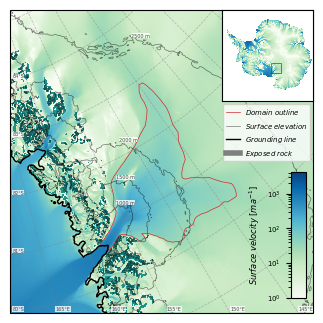

In [51]:
## geographical setting

x0 = 0.2e6
x1 = 0.8e6
y0 = -1.1e6
y1 = -0.5e6

cmap = 'GnBu'
vmin = 1e0

fig,ax = plt.subplots(nrows=1,ncols=1,figsize=[8.5*cm,8.5*cm],subplot_kw={"projection": proj})

a = ax.pcolormesh(xv,yv,vel,norm=LogNorm(vmin=vmin),cmap=cmap,transform=proj)
b = ax.contour(xs,ys,s[:],levels=[1000,1500,2000,2500,3000],linewidths=0.5,alpha=0.5,colors='k',transform=proj)
c = ax.contour(xs,ys,groundingline,[0.5],linewidths=1,colors='k',transform=proj)
d = ax.contourf(xs,ys,rock,transform=proj,levels=[0.5,1.5],color=['tab:gray'])

# ax.clabel(b, inline=True, fontsize=3.5) #, fmt='%d')

outline = Polygon(vertices, closed=True, fill=False, edgecolor='tab:red',linewidth=0.5)
ax.add_patch(outline)

ax.set_xlim(x0,x1)
ax.set_ylim(y0,y1)

ax.set_aspect(1)
ax.set(yticklabels=[])
ax.set(xticklabels=[])

cax = ax.inset_axes([0.925,0.05,0.05,0.415])
cbar = fig.colorbar(a, cax=cax,orientation='vertical')#, location="right", pad=0.05, shrink=0.88)
cbar.ax.tick_params(labelsize=fs-1)
# cbar.ax.set_title('$Surface\ velocity\ [m a^{-1}]$',fontsize=fs-1)#,x=1.3,pad=-0)
cbar.set_label('$Surface\ velocity\ [m a^{-1}]$',fontsize=fs)
cbar.ax.yaxis.set_ticks_position('left')
cbar.ax.yaxis.set_label_position('left')

gl = ax.gridlines(
crs=ccrs.PlateCarree(),
draw_labels=False,      # don't label the outside
linewidth=0.5,
color='gray',
alpha=0.5,
linestyle='--'
)
# gl.zorder = 1
gl.xlocator = mticker.FixedLocator(range(-180, 181, 5))
gl.ylocator = mticker.FixedLocator(range(-90, -59, 1))

# Surface elevation labels
for el,xx,yy in zip([1000,1500,2000,2500],[410000,410000,415000,440000],[-885000,-835000,-760000,-555000]):
    ax.text(
        xx, yy,
        f"{el} m",
        fontsize=3.5,
        color="0.3",
        bbox=dict(
            facecolor="white",
            edgecolor="none",   # or "black"
            alpha=0.8,
            pad=0.1
        )
    )

# Latitude labels
for lat,yy in zip(range(-84, -79, 1),[-635000,-750000,-865000,-980000,-1095000]):
    ax.text(
        205000, yy,
        f"{-1*lat}°S",
        fontsize=3.5,
        color="0.3",
        bbox=dict(
            facecolor="white",
            edgecolor="none",   # or "black"
            alpha=0.8,
            pad=0.1
        )
    )

# Longitude labels
for lon,xx in zip([165,160,155,150,145],[290000,400000,510000,635000,770000]):
    ax.text(
        xx, -1095000,
        f"{lon}°E",
        fontsize=3.5,
        color="0.3",
        bbox=dict(
            facecolor="white",
            edgecolor="none",   # or "black"
            alpha=0.8,
            pad=0.1
        )
    )

axins = ax.inset_axes([0.7,0.7,0.3,0.3])
axins.pcolormesh(xv,yv,vel,norm=LogNorm(vmin=vmin),cmap=cmap)
axins.plot([x0,x1,x1,x0,x0],[y0,y0,y1,y1,y0],color='red',linewidth=0.5)
axins.set(yticklabels=[])
axins.set(xticklabels=[])
axins.set(xticks=[])
axins.set(yticks=[])

fig.tight_layout()

legend_surf = Line2D([0], [0],linewidth=0.5,alpha=0.5,color='k',label='$Surface\ elevation$')
legend_gl = Line2D([0], [0],linewidth=1,color='k',label='$Grounding\ line$')
legend_rock = Line2D([0],[0],linewidth=4,color='tab:gray')
legend_domain = Line2D([0],[0],linewidth=0.5,color='tab:red')

ax.legend(
    loc="upper left",
    bbox_to_anchor=(0.69, 0.7),
    # mode='expand',
    frameon=True,
    fontsize=fs-1,
    handles=[legend_domain,legend_surf,legend_gl,legend_rock],#,legend_gradient],
    labels=['$Domain\ outline$','$Surface\ elevation$', '$Grounding\ line$', '$Exposed\ rock$'],#,'$Surface\ velocity\ [m a^{-1}$]'],
)
# plt.show()

plt.savefig(f'{figurepath}Fig-geogr-setting.png',dpi=300,pad_inches=0.,bbox_inches=None)

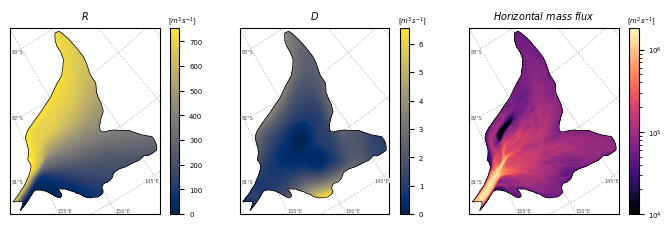

In [68]:
## D,R

glacier = 'Byrd' 

Rmean = np.nanmean(np.where(inside_v,R,np.nan))
Dmean = np.nanmean(np.where(inside_v,D,np.nan))
Rnorm = np.where(inside_v,R - Rmean,np.nan)
Dnorm = np.where(inside_v,D - Dmean,np.nan)
Rnorm = Rnorm - np.nanmin(Rnorm)
Dnorm = Dnorm - np.nanmin(Dnorm)
mf_p = np.where(inside_v,mf_p,np.nan)

if glacier == 'Denman':
    fig, ((ax1),(ax2),(ax3)) = plt.subplots(nrows=3,ncols=1,figsize=[8.5*cm,10*cm])
elif glacier == 'Byrd':
    fig, ((ax1,ax2,ax3)) = plt.subplots(nrows=1,ncols=3,figsize=[17.9*cm,6*cm],subplot_kw={"projection": proj})

a1 = ax1.pcolormesh(Xv,Yv,Rnorm.reshape((Xv.shape[0],Xv.shape[1])),cmap='cividis',shading='gouraud',transform=proj)
a2 = ax2.pcolormesh(Xv,Yv,Dnorm.reshape((Xv.shape[0],Xv.shape[1])),cmap='cividis',shading='gouraud',transform=proj)
a3 = ax3.pcolormesh(Xv,Yv,(spy*mf_p).reshape((Xv.shape[0],Xv.shape[1])),shading='gouraud',cmap='magma',norm=LogNorm(vmin=1e4),transform=proj)

for ax,a in zip([ax1, ax2, ax3],[a1, a2, a3]):
    outline = Polygon(vertices, closed=True, fill=False, edgecolor='black',linewidth=0.5)
    ax.add_patch(outline)
    Artist.set_clip_path(a,outline)
    ax.set_aspect(1)
    ax.set(yticklabels=[])
    ax.set(xticklabels=[])

    ax.margins(x=0.02, y=0.02)

    gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=False,      # don't label the outside
    linewidth=0.5,
    color='gray',
    alpha=0.5,
    linestyle='--'
    )
    gl.zorder = 0
    gl.xlocator = mticker.FixedLocator(range(-180, 181, 5))
    gl.ylocator = mticker.FixedLocator(range(-90, -59, 1))

    # Latitude labels
    for lat,y0 in zip(range(-83, -80, 1),[-687000,-812000,-932000]):
        ax.text(
            373000, y0,
            f"{-1*lat}°S",
            fontsize=3.5,
            color="0.3",
            bbox=dict(
                facecolor="white",
                edgecolor="none",   # or "black"
                alpha=0.8,
                pad=0.1
            )
        )

    # Longitude labels
    for lon,x0,y0 in zip([155,150,145],[460000,570000,625000],[-987000,-987000,-930000]):
        ax.text(
            x0, y0,
            f"{lon}°E",
            fontsize=3.5,
            color="0.3",
            bbox=dict(
                facecolor="white",
                edgecolor="none",   # or "black"
                alpha=0.8,
                pad=0.1
            )
        )
    
    cbar = fig.colorbar(a, ax=ax, location="right", pad=0.05)#, shrink=0.88)
    cbar.ax.tick_params(labelsize=fs-1)
    if ax == ax1:
        cbar.ax.set_title('$[m^3 s^{-1}]$',fontsize=fs-1,x=1.3,pad=-0)
    elif ax == ax2:
        cbar.ax.set_title('$[m^3 s^{-1}]$',fontsize=fs-1,x=1.3,pad=-0)
    elif ax == ax3:
        cbar.ax.set_title('$[m^2 s^{-1}]$',fontsize=fs-1,x=1.3,pad=-0)


ax1.set_title('$R$',fontsize=fs+1)
ax2.set_title('$D$',fontsize=fs+1)
ax3.set_title('$Horizontal\ mass\ flux$',fontsize=fs+1)

fig.tight_layout()
    
# plt.show()

plt.savefig('/private/var/phys-admin/Documents/Jakob/MC-SSA/figures/Fig-mass-flux.png',dpi=300,pad_inches=0.,bbox_inches=None)


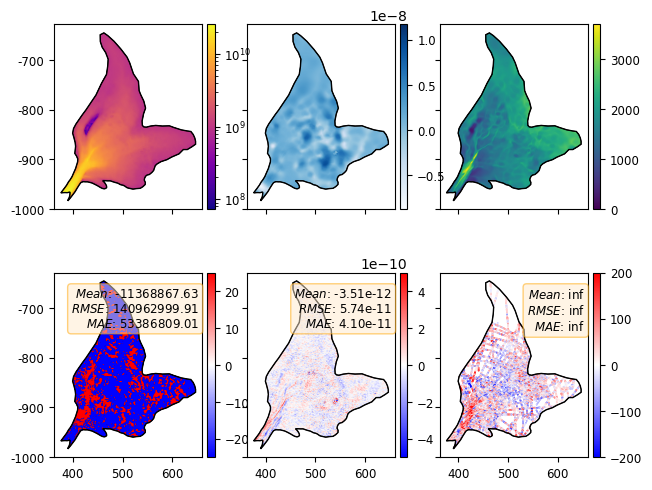

In [30]:
# prediction vs observations

glacier = 'Byrd' # or 'Byrd'

vel_p = spy * np.where(inside_v,vel_p,np.nan)
vel_diff = spy * np.where(inside_v,vel_diff,np.nan)
smb_p = np.where(inside_smb,smb_p,np.nan)
smb_diff = np.where(inside_smb,smb_diff,np.nan)
H_pfull = np.where(inside_s,H_pfull,np.nan)

# grid smb data
xg = np.unique(Xsmb)
yg = np.unique(Ysmb)
PRED = np.full((len(yg),len(xg)),np.nan)
REAL = np.full((len(yg),len(xg)),np.nan)
DIFF = np.full((len(yg),len(xg)),np.nan)
ix = np.searchsorted(xg,Xsmb)
iy = np.searchsorted(yg,Ysmb)
PRED[iy,ix] = smb_p.reshape([len(smb_p),1])
REAL[iy,ix] = smb_crop.reshape([len(smb_p),1])
DIFF[iy,ix] = smb_diff.reshape([len(smb_p),1])
DIFF_REL = DIFF/REAL

vrel = 0.1 * 100.
norm_rel = TwoSlopeNorm(vmin=-1*vrel, vcenter=0., vmax=vrel)

cmapdiff = 'bwr'

if glacier == 'Denman':
    fig, ((ax1,ax2),(ax3,ax4),(ax5,ax6)) = plt.subplots(nrows=3,ncols=2,figsize=[17.9*cm,10*cm])
elif glacier == 'Byrd':
    fig, ((ax1,ax3,ax5),(ax2,ax4,ax6)) = plt.subplots(nrows=2,ncols=3,figsize=[17.9*cm,15*cm])

a1 = ax1.pcolormesh(Xv,Yv,(vel_p).reshape((Xv.shape[0],Xv.shape[1])),shading='gouraud',cmap='plasma',norm=LogNorm())
a2 = ax2.pcolormesh(Xv,Yv,vel_diff.reshape((Xv.shape[0],Xv.shape[1])),shading='gouraud',cmap=cmapdiff,vmax=25,vmin=-25)

a3 = ax3.pcolormesh(xg,yg,PRED,shading='gouraud',cmap='Blues')#,vmin=vmin,vmax=vmax)
# a4 = ax4.pcolormesh(xg,yg,100*DIFF_REL,shading='gouraud',cmap='seismic',norm=norm_rel)
a4 = ax4.pcolormesh(xg,yg,DIFF,shading='gouraud',cmap=cmapdiff,vmin=-5e-10,vmax=5e-10)#,norm=norm_rel)

a5 = ax5.pcolormesh(Xs,Ys,H_pfull.reshape((Xs.shape[0],Xs.shape[1])),cmap='viridis',shading='gouraud',vmin=0.)#,vmax=vmax)
a6 = ax6.scatter(XH,YH,c=H_diff,s=0.02,cmap=cmapdiff,vmin=-200.,vmax=200.)

for ax,a in zip([ax1, ax2, ax3, ax4, ax5, ax6],[a1, a2, a3, a4, a5, a6]):
    outline = Polygon(vertices, closed=True, fill=False, edgecolor='black')
    ax.add_patch(outline)
    Artist.set_clip_path(a,outline)
    ax.set_aspect(1)


for ax,a in zip([ax1, ax2, ax3, ax4, ax5, ax6],[a1, a2, a3, a4, a5, a6]):
    outline = Polygon(vertices, closed=True, fill=False, edgecolor='black',linewidth=0.5)
    ax.add_patch(outline)
    Artist.set_clip_path(a,outline)
    ax.set_aspect(1)
    ax.tick_params(axis='both', which='major', labelsize=fs)
    ax.tick_params(axis='both', which='minor', labelsize=fs)

    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))
    
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.05)
    cbar = plt.colorbar(a,ax=ax,location='right',cax=cax)
    cbar.ax.tick_params(labelsize=fs)

for ax,diff in zip([ax2,ax6],[vel_diff,H_diff]):
    stats = (f'$Mean$: {np.nanmean(diff):.2f}\n'
            f'$RMSE$: {np.sqrt(np.nanmean(np.square(diff))):.2f}\n'
            f'$MAE$: {np.nanmean(np.abs(diff)):.2f}'
            )
    bbox = dict(boxstyle='round', fc='blanchedalmond', ec='orange', alpha=0.5)
    ax.text(0.98, 0.92, stats, fontsize=fs, bbox=bbox, transform=ax.transAxes, ha='right', va='top')

for ax,diff in zip([ax4],[DIFF]):
    stats = (f'$Mean$: {np.nanmean(diff):.2e}\n'
            f'$RMSE$: {np.sqrt(np.nanmean(np.square(diff))):.2e}\n'
            f'$MAE$: {np.nanmean(np.abs(diff)):.2e}'
            )
    bbox = dict(boxstyle='round', fc='blanchedalmond', ec='orange', alpha=0.5)
    ax.text(0.98, 0.92, stats, fontsize=fs, bbox=bbox, transform=ax.transAxes, ha='right', va='top')

for ax in [ax1, ax3, ax5]:
    ax.set(xticklabels=[])

for ax in [ax3, ax4, ax5, ax6]:
    ax.set(yticklabels=[])

plt.show()


In [61]:
import matplotlib.colors as mcolors

In [72]:
# Number of colors allocated to each side
nwater = 128
nland = 128

# Ocean: dark to light blue
ocean = plt.cm.Blues_r(np.linspace(0.2, 1, nwater))

# Land: green to brown
land = plt.cm.Greens_r(np.linspace(0.25, 1.0, nland))

# Combine them
colors = np.vstack((ocean, land))
cmapTerrain = mcolors.ListedColormap(colors)

# Make 0 correspond to the join
vmin = -3200.
vmax = 1500.
vbound = 500

normTerrain = mcolors.TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)

/var/folders/t9/yhgh3bkn0rv9cwrp0h8668qc0000gq/T/ipykernel_99027/776628291.py:38: MatplotlibDeprecationWarning: Since Matplotlib 3.10 indicate_inset_[zoom] returns a single InsetIndicator artist with a rectangle property and a connectors property.  From 3.12 it will no longer be possible to unpack the return value into two elements.
  rect1,conn1 = ax1.indicate_inset_zoom(axins1, edgecolor="black")
/var/folders/t9/yhgh3bkn0rv9cwrp0h8668qc0000gq/T/ipykernel_99027/776628291.py:39: MatplotlibDeprecationWarning: Since Matplotlib 3.10 indicate_inset_[zoom] returns a single InsetIndicator artist with a rectangle property and a connectors property.  From 3.12 it will no longer be possible to unpack the return value into two elements.
  rect2,conn2 = ax1.indicate_inset_zoom(axins2, edgecolor="black")
/var/folders/t9/yhgh3bkn0rv9cwrp0h8668qc0000gq/T/ipykernel_99027/776628291.py:55: MatplotlibDeprecationWarning: Since Matplotlib 3.10 indicate_inset_[zoom] returns a single InsetIndicator artist w

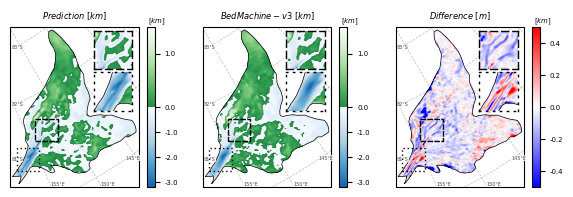

In [73]:
fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=[17.9*cm,12*cm],subplot_kw={"projection": proj})

# poly_path = Path(vertices)
# inside_s = poly_path.contains_points(XYs)

b_p = np.where(inside_s,bed_p,np.nan)
# b_diff = np.where(inside_s,bed_diff,np.nan)
bmbed = np.where(inside_s,bedcrop.flatten(),np.nan)
b_diff = b_p - bmbed

# vmin = -3200.
# vmax = 1500.
# vbound = 500

# normTerrain = mcolors.TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)

cmap = 'terrain' # 'gist_earth' # 'viridis' # 'copper' # 
cmapdiff = 'bwr' # 'coolwarm' # 'seismic' # 

a1 = ax1.pcolormesh(Xs,Ys,b_p.reshape((Xs.shape[0],Xs.shape[1])),cmap=cmapTerrain,shading='gouraud',norm=normTerrain,transform=proj)
a2 = ax2.pcolormesh(Xs,Ys,bmbed.reshape((Xs.shape[0],Xs.shape[1])),shading='gouraud',cmap=cmapTerrain,norm=normTerrain,transform=proj)
a3 = ax3.pcolormesh(Xs,Ys,b_diff.reshape((Xs.shape[0],Xs.shape[1])),shading='gouraud',cmap=cmapdiff,vmin=-1*vbound,vmax=vbound,transform=proj)

x1, x2, y1, y2 = 3.85e5, 4.35e5, -9.55e5, -9.05e5  # subregion of the original image
axins1 = ax1.inset_axes(
    [0.65, 0.36, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai1 = axins1.pcolormesh(Xs,Ys,b_p.reshape((Xs.shape[0],Xs.shape[1])),cmap=cmapTerrain,shading='gouraud',norm=normTerrain)
axins1.set_aspect(1)

x1, x2, y1, y2 = 4.25e5, 4.75e5, -8.9e5, -8.4e5  # subregion of the original image
axins2 = ax1.inset_axes(
    [0.65, 0.62, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai2 = axins2.pcolormesh(Xs,Ys,b_p.reshape((Xs.shape[0],Xs.shape[1])),cmap=cmapTerrain,shading='gouraud',norm=normTerrain)
axins1.set_aspect(1)

rect1,conn1 = ax1.indicate_inset_zoom(axins1, edgecolor="black")
rect2,conn2 = ax1.indicate_inset_zoom(axins2, edgecolor="black")

x1, x2, y1, y2 = 3.85e5, 4.35e5, -9.55e5, -9.05e5  # subregion of the original image
axins3 = ax2.inset_axes(
    [0.65, 0.36, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai3 = axins3.pcolormesh(Xs,Ys,bmbed.reshape((Xs.shape[0],Xs.shape[1])),shading='gouraud',cmap=cmapTerrain,norm=normTerrain)
axins3.set_aspect(1)

x1, x2, y1, y2 = 4.25e5, 4.75e5, -8.9e5, -8.4e5  # subregion of the original image
axins4 = ax2.inset_axes(
    [0.65, 0.62, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai4 = axins4.pcolormesh(Xs,Ys,bmbed.reshape((Xs.shape[0],Xs.shape[1])),shading='gouraud',cmap=cmapTerrain,norm=normTerrain)
axins4.set_aspect(1)

rect3,conn3 = ax2.indicate_inset_zoom(axins3, edgecolor="black")
rect4,conn4 = ax2.indicate_inset_zoom(axins4, edgecolor="black")

x1, x2, y1, y2 = 3.85e5, 4.35e5, -9.55e5, -9.05e5  # subregion of the original image
axins5 = ax3.inset_axes(
    [0.65, 0.36, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai5 = axins5.pcolormesh(Xs,Ys,b_diff.reshape((Xs.shape[0],Xs.shape[1])),shading='gouraud',cmap=cmapdiff,vmin=-1*vbound,vmax=vbound)
axins5.set_aspect(1)

x1, x2, y1, y2 = 4.25e5, 4.75e5, -8.9e5, -8.4e5  # subregion of the original image
axins6 = ax3.inset_axes(
    [0.65, 0.62, 0.3, 0.47],
    xlim=(x1, x2), ylim=(y1, y2), xticklabels=[], yticklabels=[])
ai6 = axins6.pcolormesh(Xs,Ys,b_diff.reshape((Xs.shape[0],Xs.shape[1])),shading='gouraud',cmap=cmapdiff,vmin=-1*vbound,vmax=vbound)
axins6.set_aspect(1)

rect5,conn5 = ax3.indicate_inset_zoom(axins3, edgecolor="black")
rect6,conn6 = ax3.indicate_inset_zoom(axins4, edgecolor="black")

for conn in [conn1,conn2,conn3,conn4,conn5,conn6]:
    for c in conn:
        c.set_visible(False)

for axin in [axins1,axins2,axins3,axins4,axins5,axins6]:
    axin.set_xticks([])
    axin.set_yticks([])

for ax,a in zip([ax1, ax2, ax3, axins1, axins3, axins5, axins2, axins4, axins6],[a1, a2, a3, ai1, ai3, ai5, ai2, ai4, ai6]):
    outline = Polygon(vertices, closed=True, fill=False, edgecolor='black',linewidth=0.5)
    ax.add_patch(outline)

    Artist.set_clip_path(a,outline)
    ax.set_aspect(1)

for ax,a in zip([ax1, ax2, ax3],[a1, a2, a3]):
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))

    ax.margins(x=0.02, y=0.02)

    gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=False,      # don't label the outside
    linewidth=0.5,
    color='gray',
    alpha=0.5,
    linestyle='--'
    )
    gl.zorder = 0
    gl.xlocator = mticker.FixedLocator(range(-180, 181, 5))
    gl.ylocator = mticker.FixedLocator(range(-90, -59, 1))

    # Latitude labels
    for lat,y0 in zip(range(-83, -80, 1),[-687000,-812000,-932000]):
        ax.text(
            373000, y0,
            f"{-1*lat}°S",
            fontsize=3.5,
            color="0.3",
            bbox=dict(
                facecolor="white",
                edgecolor="none",   # or "black"
                alpha=0.8,
                pad=0.1
            )
        )

    # Longitude labels
    for lon,x0,y0 in zip([155,150,145],[460000,570000,625000],[-987000,-987000,-930000]):
        ax.text(
            x0, y0,
            f"{lon}°E",
            fontsize=3.5,
            color="0.3",
                bbox=dict(
                facecolor="white",
                edgecolor="none",   # or "black"
                alpha=0.8,
                pad=0.1
            )
        )
    
    
# for ax,a in zip([ax1, ax2],[a1, a2]):
#     divider = make_axes_locatable(ax)
#     cax = divider.append_axes("right", size="5%", pad=0.05)
#     cbar = plt.colorbar(a,ax=ax,location='right',cax=cax)
#     cbar.ax.tick_params(labelsize=fs)
#     cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))

# for ax,a in zip([ax3],[a3]):
#     divider = make_axes_locatable(ax)
#     cax = divider.append_axes("right", size="5%", pad=0.05)
#     cbar = plt.colorbar(a,ax=ax,location='right',cax=cax)
#     cbar.ax.tick_params(labelsize=fs)

for ax,a in zip([ax1, ax2, ax3],[a1, a2, a3]):
    cbar = fig.colorbar(a, ax=ax, location="right", pad=0.05, shrink=0.44)
    cbar.ax.tick_params(labelsize=fs-1)
    cbar.ax.set_title('$[km]$',fontsize=fs-1,x=1.3,pad=-0)
    # if a in [a3]:
    cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.1f}'))
    # else:    
    #     cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-3:.0f}'))
    

for axin in [axins1,axins3,axins5]:
    for spine in axin.spines.values():
        # spine.set_edgecolor('red')
        spine.set_linestyle((0,(1,4)))
        spine.set_linewidth(1)

for axin in [axins2,axins4,axins6]:
    for spine in axin.spines.values():
        # spine.set_edgecolor('cyan')
        spine.set_linestyle((0,(5,3)))
        spine.set_linewidth(1)

for rect in [rect1,rect3,rect5]:
    rect.set_linestyle((0,(1,2)))
    rect.set_linewidth(1)
    rect.set_edgecolor('black')
    rect.set_alpha(1)

for rect in [rect2,rect4,rect6]:
    rect.set_linestyle((0,(4,1)))
    rect.set_linewidth(1)
    rect.set_edgecolor('black')
    rect.set_alpha(1)

# for ax,diff in zip([ax1],[b_p]):
#     stats = (f'$Max$: {np.nanmax(diff):.0f}\n'
#             f'$Min$: {np.nanmin(diff):.0f}\n'
#             )
#     bbox = dict(boxstyle='round', fc='blanchedalmond', ec='orange', alpha=0.5)
#     ax.text(0.05, 0.95, stats, fontsize=fs, bbox=bbox, transform=ax.transAxes, ha='left', va='top')

# fig.suptitle('$Ice\ sheet\ bed\ elevation$')
ax1.set_title('$Prediction\ [km]$',fontsize=fs)
ax2.set_title('$BedMachine-v3\ [km]$',fontsize=fs)
ax3.set_title('$Difference\ [m]$',fontsize=fs)

ax2.set(yticklabels=[])
ax3.set(yticklabels=[])

plt.savefig(f'{figurepath}Fig-comparison-BedMachine.png',dpi=300,pad_inches=0.,bbox_inches=None)
